# Feature Selection and Feature Correlations

This notebook builds upon the previous one and removes all features with an importance score of less than 0.01. This threshold was guided by the results produced from the previous notebook. Following the feature selection, the focus switched to feature engineering, where correlations between the remaining features are investigated to figure out how they can be combined to produce new features.

## Importing Libraries and packages

In [1]:
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns

In [2]:
# Loading in the dataset
df = pd.read_csv('ml_dataset.csv')

# Separating the response variable (y) from the set of predictor variables (X)
X = df.iloc[:, 0:-1]
y = df.iloc[:, -1]

# List of relevant features according to feature importance
relevant_features = ['steps_per_hour', 'calories_per_hour', 'total_intensities_per_hour', 'average_intensities_per_hour',
                     'hour_of_day', 'day_of_week', 'steps_per_minute', 'calories_per_minute', 'total_steps_per_day', 
                     'total_calories_per_day', 'days_recorded']

X = X[relevant_features]

X.head()

,steps_per_hour,calories_per_hour,total_intensities_per_hour,average_intensities_per_hour,hour_of_day,day_of_week,steps_per_minute,calories_per_minute,total_steps_per_day,total_calories_per_day,days_recorded
0,0,84,0,0.00,18,6,0,1.40,0,0,61
1,126,108,7,0.12,13,6,14,3.92,0,0,61
2,939,192,33,0.55,21,6,48,5.32,0,0,61
3,321,126,13,0.22,22,6,0,1.68,0,0,61
4,136,120,11,0.18,21,6,8,3.64,0,0,61


In [3]:
X.shape

(574807, 11)

In [4]:
X.describe()

,steps_per_hour,calories_per_hour,total_intensities_per_hour,average_intensities_per_hour,hour_of_day,day_of_week,steps_per_minute,calories_per_minute,total_steps_per_day,total_calories_per_day,days_recorded
count,574807.000000,574807.000000,574807.000000,574807.000000,574807.000000,574807.000000,574807.000000,574807.000000,574807.000000,574807.000000,574807.000000
mean,332.304328,96.954722,12.699285,0.211774,11.453152,3.968532,5.477691,1.614376,8259.987170,2318.709008,59.121509
std,640.192385,60.137863,21.228401,0.353765,6.920857,2.005540,17.491820,1.397270,4294.052197,807.979186,5.591081
min,0.000000,42.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.700000,0.000000,0.000000,30.000000
25%,0.000000,62.000000,0.000000,0.000000,5.000000,2.000000,0.000000,0.930000,4832.000000,1776.000000,60.000000
50%,74.000000,81.000000,5.000000,0.080000,11.000000,4.000000,0.000000,1.170000,8585.000000,2180.000000,61.000000
75%,376.000000,112.000000,17.000000,0.280000,17.000000,6.000000,0.000000,1.500000,11207.000000,2859.000000,61.000000
max,7801.000000,669.000000,180.000000,3.000000,23.000000,7.000000,186.000000,19.260000,22770.000000,4900.000000,61.000000


In [5]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 574807 entries, 0 to 574806
Data columns (total 11 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   steps_per_hour                574807 non-null  int64  
 1   calories_per_hour             574807 non-null  int64  
 2   total_intensities_per_hour    574807 non-null  int64  
 3   average_intensities_per_hour  574807 non-null  float64
 4   hour_of_day                   574807 non-null  int64  
 5   day_of_week                   574807 non-null  int64  
 6   steps_per_minute              574807 non-null  int64  
 7   calories_per_minute           574807 non-null  float64
 8   total_steps_per_day           574807 non-null  int64  
 9   total_calories_per_day        574807 non-null  int64  
 10  days_recorded                 574807 non-null  int64  
dtypes: float64(2), int64(9)
memory usage: 48.2 MB


In [6]:
X.isnull().sum()

steps_per_hour                  0
calories_per_hour               0
total_intensities_per_hour      0
average_intensities_per_hour    0
hour_of_day                     0
day_of_week                     0
steps_per_minute                0
calories_per_minute             0
total_steps_per_day             0
total_calories_per_day          0
days_recorded                   0
dtype: int64

## Feature Correlations

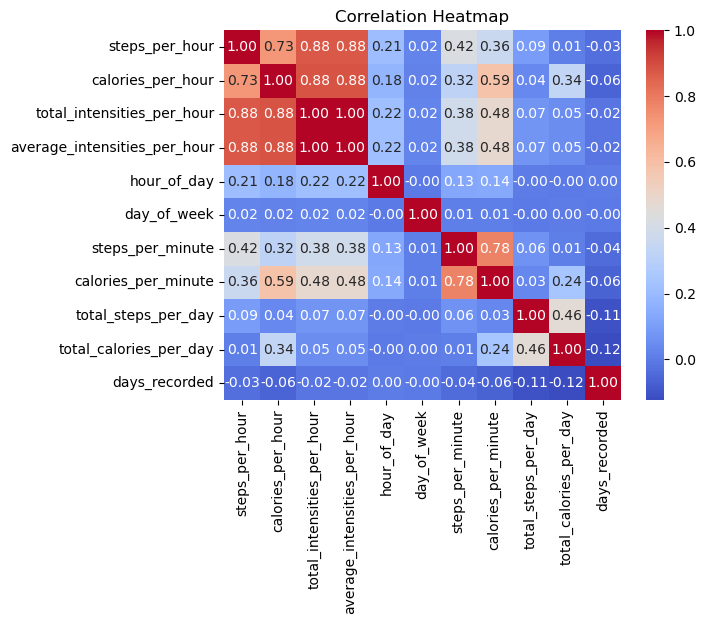

In [7]:
correlation_matrix = X.corr()
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()